# General Setup Code

In [56]:
from pathlib import Path

import snntorch as snn
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import snntorch.spikeplot as splt

from torchvision import datasets, transforms
from snntorch import utils, spikegen
from torch.utils.data import DataLoader
from IPython.display import HTML, display

In [30]:
batch_size = 128
num_classes = 10  # MNIST has 10 outputs

# Torch Variables
dtype = torch.float

# Directory paths
project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file())

data_path = project_root / "data" / "raw"
data_path.mkdir(parents=True, exist_ok=True)
figure_path = project_root / "report" / "figures"
figure_path.mkdir(parents=True, exist_ok=True)

# Tutorial 1 - Spike Encoding

In [31]:
subset = 10

transform = transforms.Compose([
    transforms.Resize((28,28)),
    transforms.Grayscale(),
    transforms.ToTensor(),
    transforms.Normalize((0,), (1,))])

mnist_train = utils.data_subset(datasets.MNIST(data_path, train=True, download=True, transform=transform), subset)
train_loader = DataLoader(mnist_train, batch_size=batch_size, shuffle=True)

print(f"Size of MNIST_train: {len(mnist_train)}")

Size of MNIST_train: 6000


In [32]:
# Temporal Dynamics
num_steps = 100

# create vector filled with 0.5
raw_vector = torch.ones(num_steps)*0.5

# pass each sample through a Bernoulli trial
rate_coded_vector = torch.bernoulli(raw_vector)

print(f"Converted vector: {rate_coded_vector}")
print(f"The output is spiking {rate_coded_vector.sum()*100/len(rate_coded_vector):.2f}% of the time.")

Converted vector: tensor([0., 1., 0., 1., 1., 0., 0., 0., 0., 1., 0., 1., 1., 1., 0., 0., 1., 1.,
        1., 0., 0., 1., 0., 0., 1., 1., 1., 1., 0., 0., 1., 0., 1., 1., 1., 0.,
        1., 0., 1., 0., 0., 0., 0., 1., 1., 0., 0., 0., 1., 0., 1., 0., 1., 0.,
        1., 0., 1., 0., 0., 1., 1., 0., 1., 1., 0., 1., 1., 0., 0., 0., 0., 1.,
        0., 1., 0., 0., 1., 0., 0., 1., 0., 1., 1., 1., 0., 1., 0., 0., 1., 0.,
        1., 1., 0., 0., 1., 1., 1., 1., 1., 0.])
The output is spiking 50.00% of the time.


In [33]:
data = iter(train_loader)
data_it, targets_it = next(data)
plt.rcParams["animation.ffmpeg_path"] = str(
    Path.home() / "Apps" / "ffmpeg" / "bin" / "ffmpeg.exe")

In [34]:
spike_data = spikegen.rate(data_it, num_steps=num_steps)
spike_data_sample = spike_data[:, 0, 0]
print(spike_data.size())
print(spike_data_sample.size())

fig, ax = plt.subplots()
anim = splt.animator(spike_data_sample, fig, ax)
video = HTML(anim.to_html5_video())
plt.close(fig)
display(video)

animation_path = figure_path / "spike_mnist_animation.mp4"
anim.save(animation_path, writer="ffmpeg")
print(f"Saved animation to {animation_path}")

torch.Size([100, 128, 1, 28, 28])
torch.Size([100, 28, 28])


Saved animation to c:\Users\willm\Projects\Programming\School Assignments\RUG-Work\Neural Networks\SNN_Project-Neural_Networks-RUG-\report\figures\spike_mnist_animation.mp4


In [35]:
spike_data = spikegen.rate(data_it, num_steps=num_steps, gain=0.25)
spike_data_sample2 = spike_data[:, 0, 0]

fig, ax = plt.subplots()
anim = splt.animator(spike_data_sample2, fig, ax)
video = HTML(anim.to_html5_video())
plt.close(fig)
display(video)

animation_path = figure_path / "spike_mnist_gain_animation.mp4"
anim.save(animation_path, writer="ffmpeg")
print(f"Saved animation to {animation_path}")

Saved animation to c:\Users\willm\Projects\Programming\School Assignments\RUG-Work\Neural Networks\SNN_Project-Neural_Networks-RUG-\report\figures\spike_mnist_gain_animation.mp4


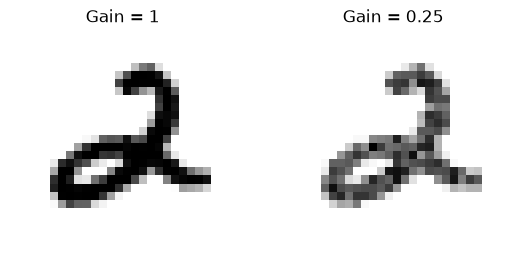

In [36]:
plt.figure(facecolor="w")
plt.subplot(1,2,1)
plt.imshow(spike_data_sample.mean(axis=0).reshape((28,-1)).cpu(), cmap='binary')
plt.axis('off')
plt.title('Gain = 1')

plt.subplot(1,2,2)
plt.imshow(spike_data_sample2.mean(axis=0).reshape((28,-1)).cpu(), cmap='binary')
plt.axis('off')
plt.title('Gain = 0.25')

plt.show()

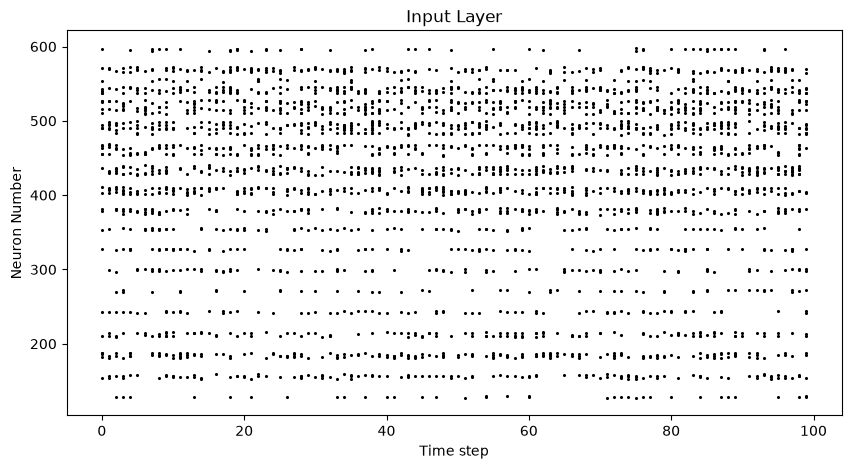

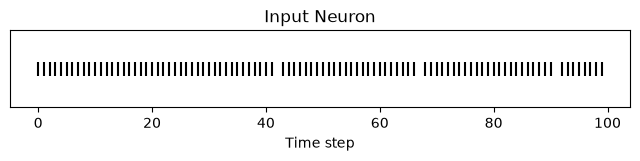

In [37]:
spike_data_sample2 = spike_data_sample2.reshape((num_steps, -1))

# raster plot
fig = plt.figure(facecolor="w", figsize=(10, 5))
ax = fig.add_subplot(111)
splt.raster(spike_data_sample2, ax, s=1.5, c="black")

plt.title("Input Layer")
plt.xlabel("Time step")
plt.ylabel("Neuron Number")
plt.show()

idx = 210  # index into 210th neuron

fig = plt.figure(facecolor="w", figsize=(8, 1))
ax = fig.add_subplot(111)

splt.raster(spike_data_sample.reshape(num_steps, -1)[:, idx].unsqueeze(1), ax, s=100, c="black", marker="|")

plt.title("Input Neuron")
plt.xlabel("Time step")
plt.yticks([])
plt.show()

In [38]:
def convert_to_time(data, tau=5, threshold=0.01):
  spike_time = tau * torch.log(data / (data - threshold))
  return spike_time

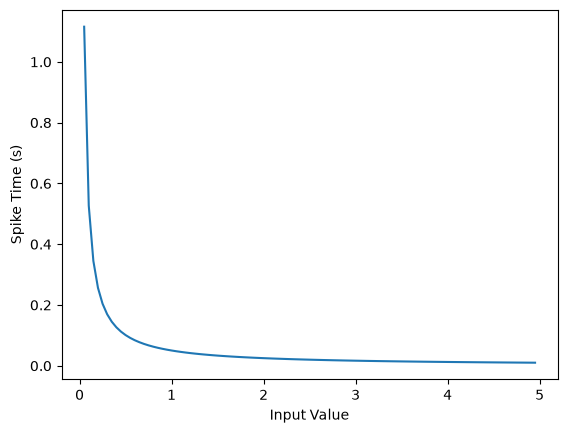

In [39]:
raw_input = torch.arange(0, 5, 0.05) # tensor from 0 to 5
spike_times = convert_to_time(raw_input)

plt.plot(raw_input, spike_times)
plt.xlabel('Input Value')
plt.ylabel('Spike Time (s)')
plt.show()

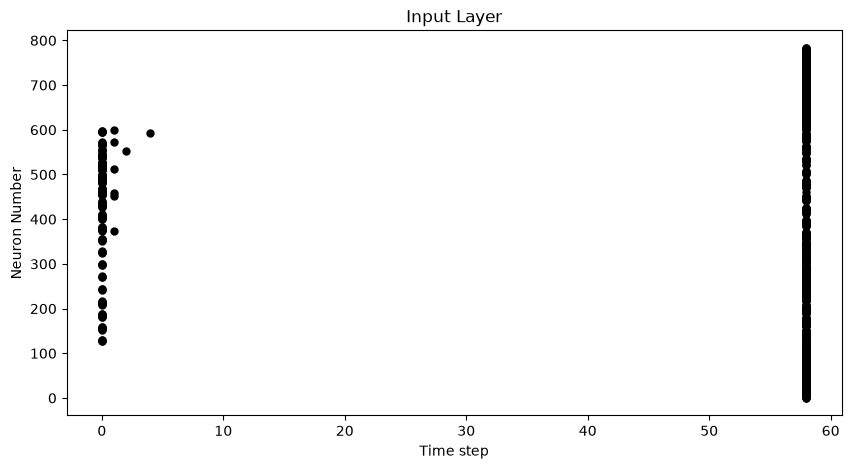

Saved image to c:\Users\willm\Projects\Programming\School Assignments\RUG-Work\Neural Networks\SNN_Project-Neural_Networks-RUG-\report\figures\spike_mnist_latency_raster.mp4


In [40]:
spike_data = spikegen.latency(data_it, num_steps=num_steps, tau=5, threshold=0.01)

fig = plt.figure(facecolor="w", figsize=(10, 5))
ax = fig.add_subplot(111)
splt.raster(spike_data[:, 0].view(num_steps, -1), ax, s=25, c="black")

plt.title("Input Layer")
plt.xlabel("Time step")
plt.ylabel("Neuron Number")
plt.show()

image_path = figure_path / "spike_mnist_latency_raster.mp4"
fig.savefig(image_path, format='png', dpi=300)
print(f"Saved image to {image_path}")

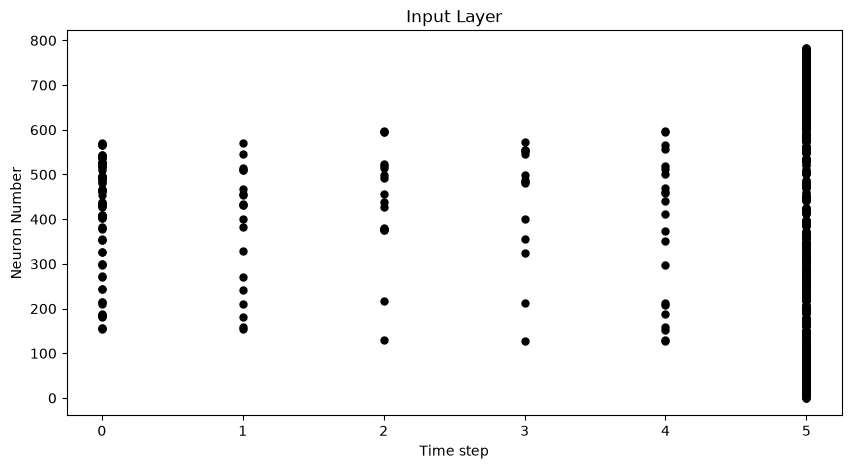

Saved image to c:\Users\willm\Projects\Programming\School Assignments\RUG-Work\Neural Networks\SNN_Project-Neural_Networks-RUG-\report\figures\spike_mnist_latency_raster_linearized.mp4


In [41]:
spike_data = spikegen.latency(data_it, num_steps=100, tau=5, threshold=0.01, linear=True)

fig = plt.figure(facecolor="w", figsize=(10, 5))
ax = fig.add_subplot(111)
splt.raster(spike_data[:, 0].view(num_steps, -1), ax, s=25, c="black")
plt.title("Input Layer")
plt.xlabel("Time step")
plt.ylabel("Neuron Number")
plt.show()

image_path = figure_path / "spike_mnist_latency_raster_linearized.mp4"
fig.savefig(image_path, format='png', dpi=300)
print(f"Saved image to {image_path}")

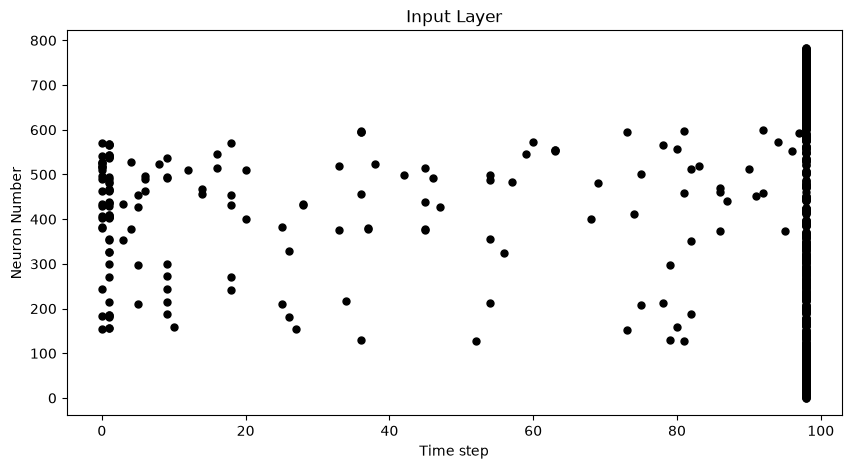

Saved image to c:\Users\willm\Projects\Programming\School Assignments\RUG-Work\Neural Networks\SNN_Project-Neural_Networks-RUG-\report\figures\spike_mnist_latency_raster_linearized_normalized.mp4


In [42]:
spike_data = spikegen.latency(data_it, num_steps=100, tau=5, threshold=0.01,
                              normalize=True, linear=True)

fig = plt.figure(facecolor="w", figsize=(10, 5))
ax = fig.add_subplot(111)
splt.raster(spike_data[:, 0].view(num_steps, -1), ax, s=25, c="black")

plt.title("Input Layer")
plt.xlabel("Time step")
plt.ylabel("Neuron Number")
plt.show()

image_path = figure_path / "spike_mnist_latency_raster_linearized_normalized.mp4"
fig.savefig(image_path, format='png', dpi=300)
print(f"Saved image to {image_path}")

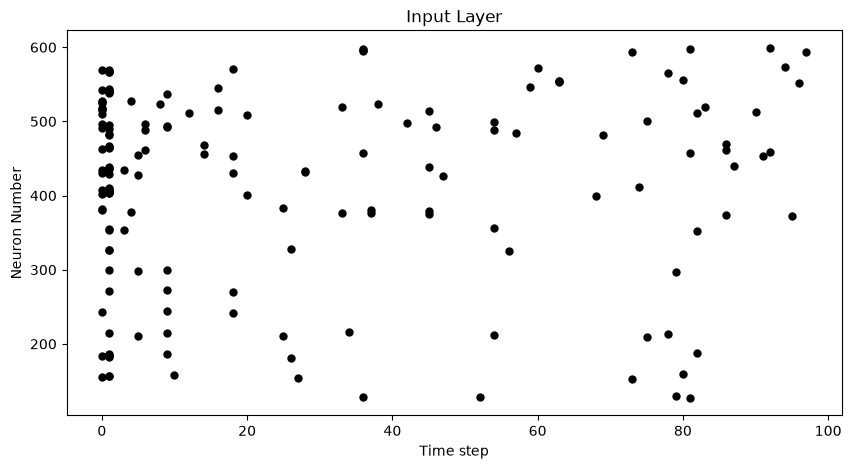

Saved image to c:\Users\willm\Projects\Programming\School Assignments\RUG-Work\Neural Networks\SNN_Project-Neural_Networks-RUG-\report\figures\spike_mnist_latency_raster_linearized_normalized_clip.mp4


In [43]:
spike_data = spikegen.latency(data_it, num_steps=100, tau=5, threshold=0.01,
                              clip=True, normalize=True, linear=True)

fig = plt.figure(facecolor="w", figsize=(10, 5))
ax = fig.add_subplot(111)
splt.raster(spike_data[:, 0].view(num_steps, -1), ax, s=25, c="black")

plt.title("Input Layer")
plt.xlabel("Time step")
plt.ylabel("Neuron Number")
plt.show()

image_path = figure_path / "spike_mnist_latency_raster_linearized_normalized_clip.mp4"
fig.savefig(image_path, format='png', dpi=300)
print(f"Saved image to {image_path}")

In [44]:
spike_data_sample = spike_data[:, 0, 0]
print(spike_data_sample.size())

fig, ax = plt.subplots()
anim = splt.animator(spike_data_sample, fig, ax)
video = HTML(anim.to_html5_video())
plt.close(fig)
display(video)

animation_path = figure_path / "spike_mnist_latency_animation_.mp4"
anim.save(animation_path, writer="ffmpeg")
print(f"Saved animation to {animation_path}")

torch.Size([100, 28, 28])


Saved animation to c:\Users\willm\Projects\Programming\School Assignments\RUG-Work\Neural Networks\SNN_Project-Neural_Networks-RUG-\report\figures\spike_mnist_latency_animation_.mp4


In [45]:
print(targets_it[0])

tensor(2)


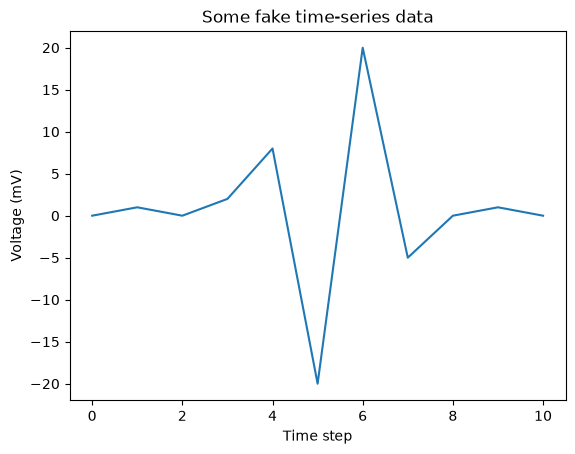

In [46]:
# Create a tensor with some fake time-series data
data = torch.Tensor([0, 1, 0, 2, 8, -20, 20, -5, 0, 1, 0])

# Plot the tensor
plt.plot(data)

plt.title("Some fake time-series data")
plt.xlabel("Time step")
plt.ylabel("Voltage (mV)")
plt.show()

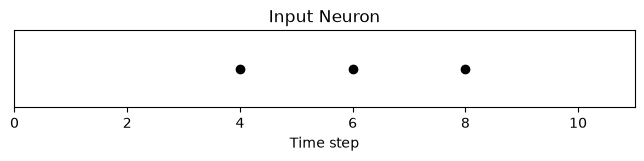

In [47]:
# Convert data
spike_data = spikegen.delta(data, threshold=4)

# Create fig, ax
fig = plt.figure(facecolor="w", figsize=(8, 1))
ax = fig.add_subplot(111)

# Raster plot of delta converted data
splt.raster(spike_data, ax, c="black")

plt.title("Input Neuron")
plt.xlabel("Time step")
plt.yticks([])
plt.xlim(0, len(data))
plt.show()

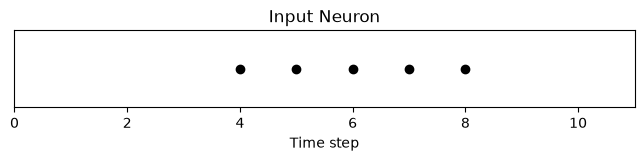

tensor([ 0.,  0.,  0.,  0.,  1., -1.,  1., -1.,  1.,  0.,  0.])


In [48]:
# Convert data
spike_data = spikegen.delta(data, threshold=4, off_spike=True)

# Create fig, ax
fig = plt.figure(facecolor="w", figsize=(8, 1))
ax = fig.add_subplot(111)

# Raster plot of delta converted data
splt.raster(spike_data, ax, c="black")

plt.title("Input Neuron")
plt.xlabel("Time step")
plt.yticks([])
plt.xlim(0, len(data))
plt.show()

print(spike_data)

In [49]:
# Create a random spike train
spike_prob = torch.rand((num_steps, 28, 28), dtype=dtype) * 0.5
spike_rand = spikegen.rate_conv(spike_prob)



fig, ax = plt.subplots()
anim = splt.animator(spike_rand, fig, ax)
video = HTML(anim.to_html5_video())
plt.close(fig)
display(video)

animation_path = figure_path / "spike_mnist_spike_generation_.mp4"
anim.save(animation_path, writer="ffmpeg")
print(f"Saved animation to {animation_path}")

Saved animation to c:\Users\willm\Projects\Programming\School Assignments\RUG-Work\Neural Networks\SNN_Project-Neural_Networks-RUG-\report\figures\spike_mnist_spike_generation_.mp4


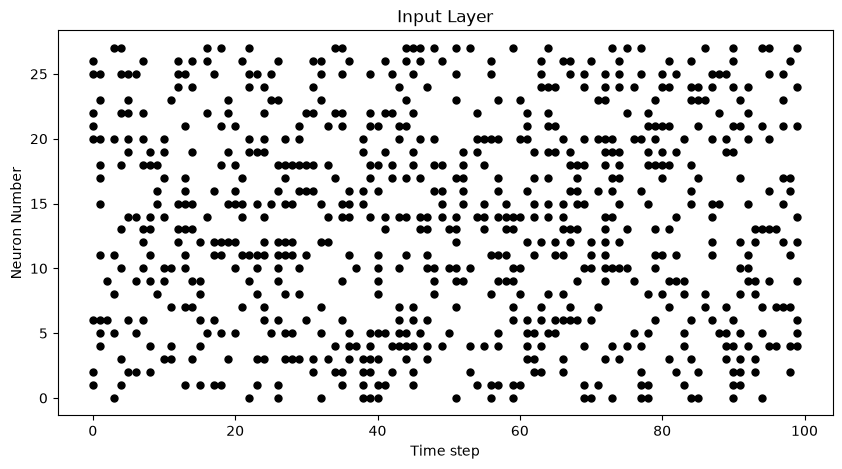

In [50]:
fig = plt.figure(facecolor="w", figsize=(10, 5))
ax = fig.add_subplot(111)
splt.raster(spike_rand[:, 0].view(num_steps, -1), ax, s=25, c="black")

plt.title("Input Layer")
plt.xlabel("Time step")
plt.ylabel("Neuron Number")
plt.show()

# Tutorial 2 - LIF Neuron Implementation

## Plotting functions

Run this cell before the Tutorial 2 simulations.

In [2]:
def plot_mem(mem, title="Membrane potential"):
    fig, ax = plt.subplots()
    ax.plot(torch.as_tensor(mem).detach().cpu())
    ax.set(xlabel="Time step", ylabel="Membrane potential", title=title)
    plt.show()
    return fig, ax


def plot_step_current_response(cur_in, mem_rec, step_onset, title="Step current response"):
    fig, axes = plt.subplots(2, 1, sharex=True)
    axes[0].plot(torch.as_tensor(cur_in).detach().cpu())
    axes[0].set_ylabel("Input current")
    axes[1].plot(torch.as_tensor(mem_rec).detach().cpu())
    axes[1].set(xlabel="Time step", ylabel="Membrane potential")
    for ax in axes:
        ax.axvline(step_onset, color="gray", linestyle="--")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return fig, axes


def plot_current_pulse_response(
    cur_in, mem_rec, title="Current pulse response", vline1=None, vline2=None,
    ylim_max1=None, ylim_max2=None
):
    fig, axes = plt.subplots(2, 1, sharex=True)
    axes[0].plot(torch.as_tensor(cur_in).detach().cpu())
    axes[0].set_ylabel("Input current")
    axes[1].plot(torch.as_tensor(mem_rec).detach().cpu())
    axes[1].set(xlabel="Time step", ylabel="Membrane potential")
    for boundary in (vline1, vline2):
        if boundary is not None:
            for ax in axes:
                ax.axvline(boundary, color="gray", linestyle="--")
    if ylim_max1 is not None:
        axes[0].set_ylim(top=ylim_max1)
    if ylim_max2 is not None:
        axes[1].set_ylim(top=ylim_max2)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return fig, axes


def compare_plots(
    cur_in1, cur_in2, cur_in3, mem_rec1, mem_rec2, mem_rec3,
    vline1, vline2, vline3, vline4, title="Current pulse comparison"
):
    fig, axes = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
    for current, mem, label in zip(
        (cur_in1, cur_in2, cur_in3),
        (mem_rec1, mem_rec2, mem_rec3),
        ("Pulse 1", "Pulse 2", "Pulse 3"),
    ):
        axes[0].plot(torch.as_tensor(current).detach().cpu(), label=label)
        axes[1].plot(torch.as_tensor(mem).detach().cpu(), label=label)
    axes[0].set_ylabel("Input current")
    axes[1].set(xlabel="Time step", ylabel="Membrane potential")
    for ax in axes:
        for boundary in (vline1, vline2, vline3, vline4):
            ax.axvline(boundary, color="gray", linestyle="--", alpha=0.5)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return fig, axes


def plot_cur_mem_spk(
    cur_in, mem_rec, spk_rec, thr_line=None, vline=None,
    ylim_max1=None, ylim_max2=None, title="Current, membrane, and spikes"
):
    fig, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 6))
    axes[0].plot(torch.as_tensor(cur_in).detach().cpu())
    axes[0].set_ylabel("Input current")
    axes[1].plot(torch.as_tensor(mem_rec).detach().cpu())
    axes[1].set_ylabel("Membrane potential")
    spikes = torch.as_tensor(spk_rec).detach().cpu()
    splt.raster(spikes.reshape(len(spikes), -1), axes[2], s=100, c="black", marker="|")
    axes[2].set(xlabel="Time step", ylabel="Output spikes", yticks=[])
    if thr_line is not None:
        axes[1].axhline(thr_line, color="red", linestyle="--", label="Threshold")
        axes[1].legend()
    if vline is not None:
        for ax in axes:
            ax.axvline(vline, color="gray", linestyle="--")
    if ylim_max1 is not None:
        axes[0].set_ylim(top=ylim_max1)
    if ylim_max2 is not None:
        axes[1].set_ylim(top=ylim_max2)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return fig, axes


def plot_spk_mem_spk(spk_in, mem_rec, spk_rec, title="Spike input response"):
    fig, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 6))
    for ax, values, label in (
        (axes[0], spk_in, "Input spikes"),
        (axes[2], spk_rec, "Output spikes"),
    ):
        spikes = torch.as_tensor(values).detach().cpu()
        splt.raster(spikes.reshape(len(spikes), -1), ax, s=100, c="black", marker="|")
        ax.set(ylabel=label, yticks=[])
    axes[1].plot(torch.as_tensor(mem_rec).detach().cpu())
    axes[1].set_ylabel("Membrane potential")
    axes[2].set_xlabel("Time step")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return fig, axes


def plot_reset_comparison(
    spk_in, mem_rec, spk_rec, mem_rec0, spk_rec0, title="Reset comparison"
):
    fig, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 6))
    spikes = torch.as_tensor(spk_in).detach().cpu()
    splt.raster(spikes.reshape(len(spikes), -1), axes[0], s=100, c="black", marker="|")
    axes[0].set(ylabel="Input spikes", yticks=[])
    axes[1].plot(torch.as_tensor(mem_rec).detach().cpu(), label="Subtract reset")
    axes[1].plot(torch.as_tensor(mem_rec0).detach().cpu(), label="Zero reset")
    axes[1].set_ylabel("Membrane potential")
    axes[1].legend()
    output_spikes = torch.cat((
        torch.as_tensor(spk_rec).detach().cpu().reshape(len(spk_rec), -1),
        torch.as_tensor(spk_rec0).detach().cpu().reshape(len(spk_rec0), -1),
    ), dim=1)
    splt.raster(output_spikes, axes[2], s=100, c="black", marker="|")
    axes[2].set(xlabel="Time step", ylabel="Output spikes", yticks=[0, 1])
    axes[2].set_yticklabels(["Subtract", "Zero"])
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return fig, axes

## Leaky neuron and current responses

In [3]:
def leaky_integrate_neuron(U, time_step=1e-3, I=0, R=5e7, C=1e-10):
  tau = R*C
  U = U + (time_step/tau)*(-U + I*R)
  return U

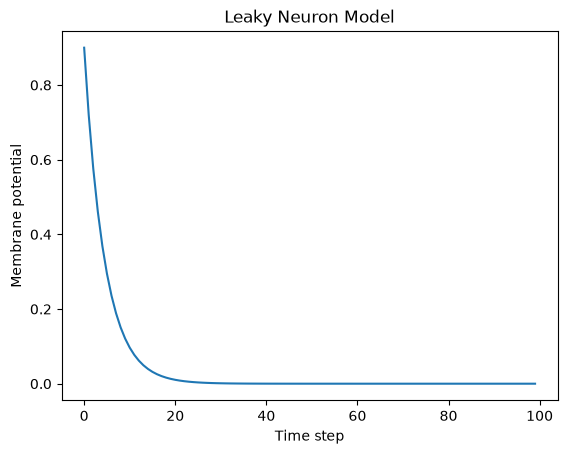

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Leaky Neuron Model'}, xlabel='Time step', ylabel='Membrane potential'>)

In [4]:
num_steps = 100
U = 0.9
U_trace = []  # keeps a record of U for plotting

for step in range(num_steps):
  U_trace.append(U)
  U = leaky_integrate_neuron(U)  # solve next step of U

plot_mem(U_trace, "Leaky Neuron Model")

In [5]:
time_step = 1e-3
R = 5
C = 1e-3

# leaky integrate and fire neuron, tau=5e-3
lif1 = snn.Lapicque(R=R, C=C, time_step=time_step)

In [6]:
# Initialize membrane, input, and output
mem = torch.ones(1) * 0.9  # U=0.9 at t=0
cur_in = torch.zeros(num_steps, 1)  # I=0 for all t
spk_out = torch.zeros(1)  # initialize output spikes

In [7]:
# A list to store a recording of membrane potential
mem_rec = [mem]

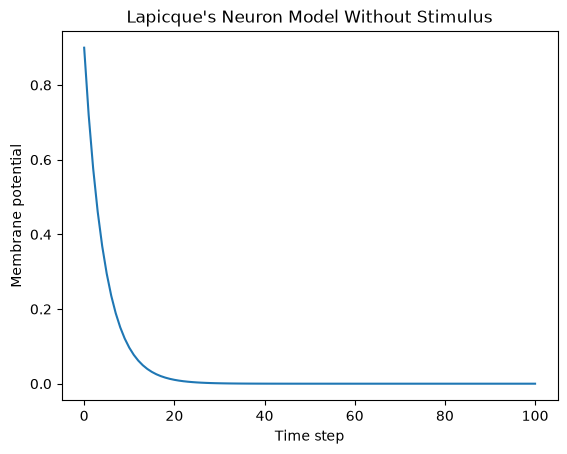

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': "Lapicque's Neuron Model Without Stimulus"}, xlabel='Time step', ylabel='Membrane potential'>)

In [8]:
# pass updated value of mem and cur_in[step]=0 at every time step
for step in range(num_steps):
  spk_out, mem = lif1(cur_in[step], mem)

  # Store recordings of membrane potential
  mem_rec.append(mem)

# convert the list of tensors into one tensor
mem_rec = torch.stack(mem_rec)

# pre-defined plotting function
plot_mem(mem_rec, "Lapicque's Neuron Model Without Stimulus")

In [9]:
# Initialize input current pulse
cur_in = torch.cat((torch.zeros(10, 1), torch.ones(190, 1)*0.1), 0)  # input current turns on at t=10

# Initialize membrane, output and recordings
mem = torch.zeros(1)  # membrane potential of 0 at t=0
spk_out = torch.zeros(1)  # neuron needs somewhere to sequentially dump its output spikes
mem_rec = [mem]

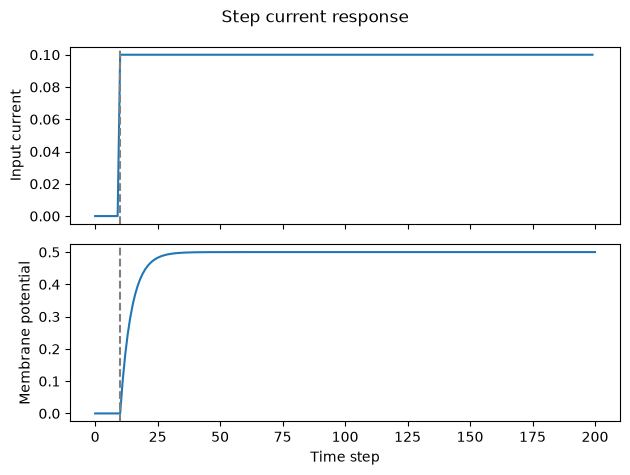

(<Figure size 640x480 with 2 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: xlabel='Time step', ylabel='Membrane potential'>],
       dtype=object))

In [10]:
num_steps = 200

# pass updated value of mem and cur_in[step] at every time step
for step in range(num_steps):
  spk_out, mem = lif1(cur_in[step], mem)
  mem_rec.append(mem)

# crunch -list- of tensors into one tensor
mem_rec = torch.stack(mem_rec)

plot_step_current_response(cur_in, mem_rec, 10)

In [11]:
print(f"The calculated value of input pulse [A] x resistance [Ω] is: {cur_in[11]*lif1.R} V")
print(f"The simulated value of steady-state membrane potential is: {mem_rec[200][0]} V")

The calculated value of input pulse [A] x resistance [Ω] is: tensor([0.5000]) V
The simulated value of steady-state membrane potential is: 0.4999999403953552 V


In [12]:
cur_in1 = torch.cat((torch.zeros(10, 1), torch.ones(20, 1)*(0.1), torch.zeros(170, 1)), 0)  # input turns on at t=10, off at t=30
mem = torch.zeros(1)
spk_out = torch.zeros(1)
mem_rec1 = [mem]

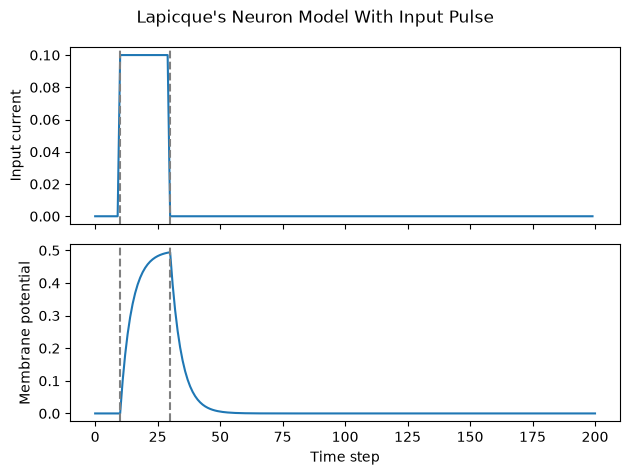

(<Figure size 640x480 with 2 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: xlabel='Time step', ylabel='Membrane potential'>],
       dtype=object))

In [13]:
# neuron simulation
for step in range(num_steps):
  spk_out, mem = lif1(cur_in1[step], mem)
  mem_rec1.append(mem)
mem_rec1 = torch.stack(mem_rec1)

plot_current_pulse_response(cur_in1, mem_rec1, "Lapicque's Neuron Model With Input Pulse",
                            vline1=10, vline2=30)

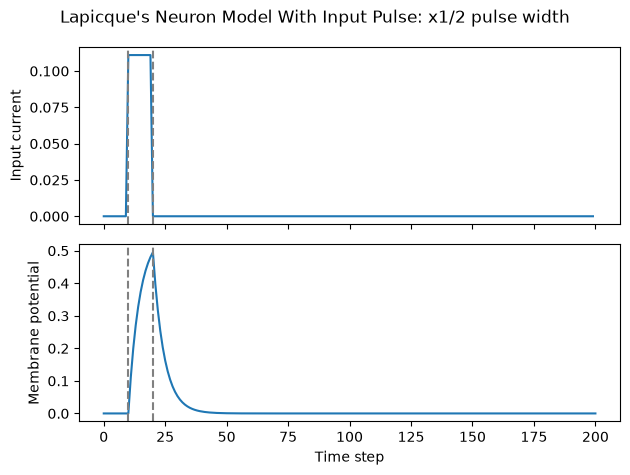

(<Figure size 640x480 with 2 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: xlabel='Time step', ylabel='Membrane potential'>],
       dtype=object))

In [14]:
# Increase amplitude of current pulse; half the time.
cur_in2 = torch.cat((torch.zeros(10, 1), torch.ones(10, 1)*0.111, torch.zeros(180, 1)), 0)  # input turns on at t=10, off at t=20
mem = torch.zeros(1)
spk_out = torch.zeros(1)
mem_rec2 = [mem]

# neuron simulation
for step in range(num_steps):
  spk_out, mem = lif1(cur_in2[step], mem)
  mem_rec2.append(mem)
mem_rec2 = torch.stack(mem_rec2)

plot_current_pulse_response(cur_in2, mem_rec2, "Lapicque's Neuron Model With Input Pulse: x1/2 pulse width",
                            vline1=10, vline2=20)

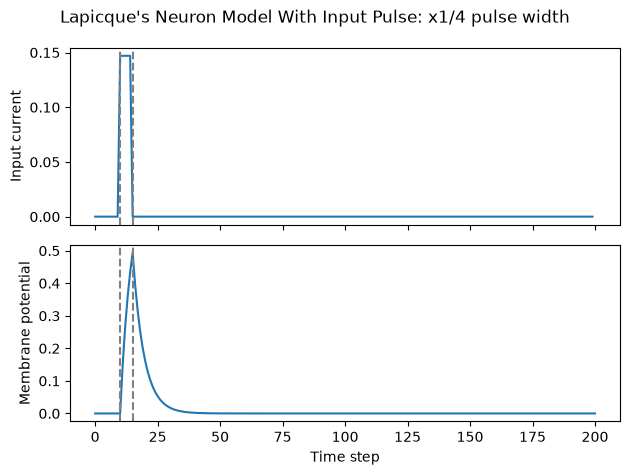

(<Figure size 640x480 with 2 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: xlabel='Time step', ylabel='Membrane potential'>],
       dtype=object))

In [15]:
# Increase amplitude of current pulse; quarter the time.
cur_in3 = torch.cat((torch.zeros(10, 1), torch.ones(5, 1)*0.147, torch.zeros(185, 1)), 0)  # input turns on at t=10, off at t=15
mem = torch.zeros(1)
spk_out = torch.zeros(1)
mem_rec3 = [mem]

# neuron simulation
for step in range(num_steps):
  spk_out, mem = lif1(cur_in3[step], mem)
  mem_rec3.append(mem)
mem_rec3 = torch.stack(mem_rec3)

plot_current_pulse_response(cur_in3, mem_rec3, "Lapicque's Neuron Model With Input Pulse: x1/4 pulse width",
                            vline1=10, vline2=15)

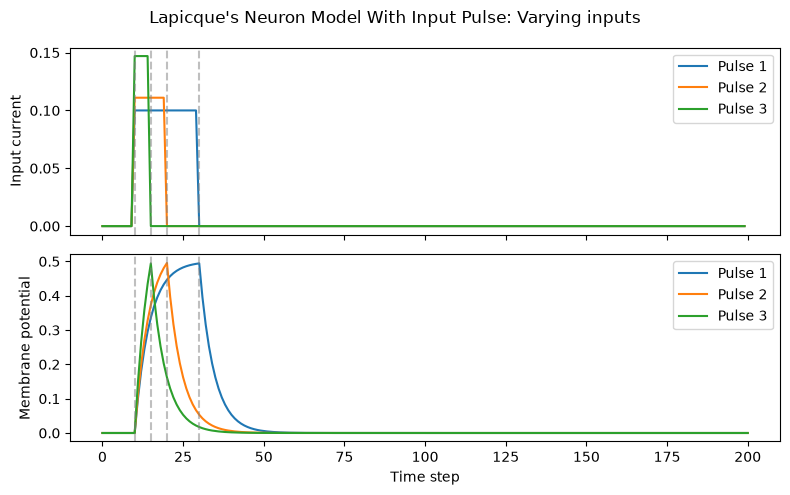

(<Figure size 800x500 with 2 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: xlabel='Time step', ylabel='Membrane potential'>],
       dtype=object))

In [16]:
compare_plots(cur_in1, cur_in2, cur_in3, mem_rec1, mem_rec2, mem_rec3, 10, 15,
              20, 30, "Lapicque's Neuron Model With Input Pulse: Varying inputs")

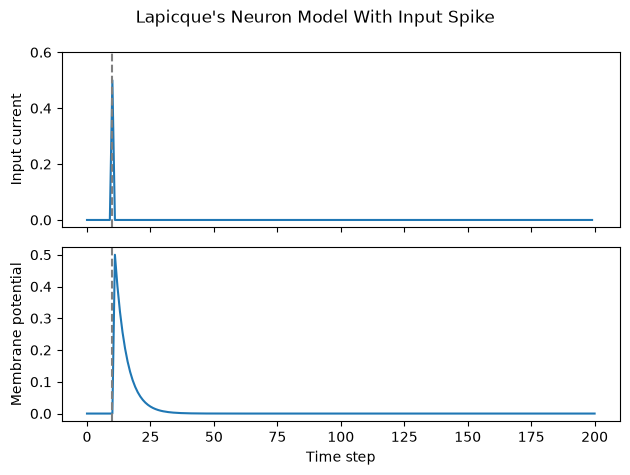

(<Figure size 640x480 with 2 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: xlabel='Time step', ylabel='Membrane potential'>],
       dtype=object))

In [17]:
# Current spike input
cur_in4 = torch.cat((torch.zeros(10, 1), torch.ones(1, 1)*0.5, torch.zeros(189, 1)), 0)  # input only on for 1 time step
mem = torch.zeros(1)
spk_out = torch.zeros(1)
mem_rec4 = [mem]

# neuron simulation
for step in range(num_steps):
  spk_out, mem = lif1(cur_in4[step], mem)
  mem_rec4.append(mem)
mem_rec4 = torch.stack(mem_rec4)

plot_current_pulse_response(cur_in4, mem_rec4, "Lapicque's Neuron Model With Input Spike",
                            vline1=10, ylim_max1=0.6)

In [18]:
# R=5.1, C=5e-3 for illustrative purposes
def leaky_integrate_and_fire(mem, cur=0, threshold=1, time_step=1e-3, R=5.1, C=5e-3):
  tau_mem = R*C
  spk = (mem > threshold) # if membrane exceeds threshold, spk=1, else, 0
  mem = mem + (time_step/tau_mem)*(-mem + cur*R)
  return mem, spk

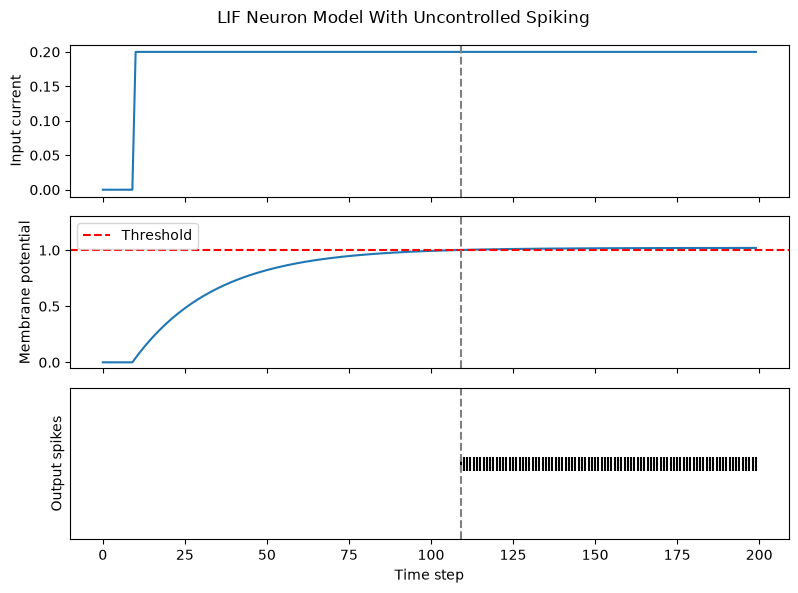

(<Figure size 800x600 with 3 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: ylabel='Membrane potential'>,
        <Axes: xlabel='Time step', ylabel='Output spikes'>], dtype=object))

In [19]:
# Small step current input
cur_in = torch.cat((torch.zeros(10), torch.ones(190)*0.2), 0)
mem = torch.zeros(1)
mem_rec = []
spk_rec = []

# neuron simulation
for step in range(num_steps):
  mem, spk = leaky_integrate_and_fire(mem, cur_in[step])
  mem_rec.append(mem)
  spk_rec.append(spk)

# convert lists to tensors
mem_rec = torch.stack(mem_rec)
spk_rec = torch.stack(spk_rec)

plot_cur_mem_spk(cur_in, mem_rec, spk_rec, thr_line=1, vline=109, ylim_max2=1.3,
                 title="LIF Neuron Model With Uncontrolled Spiking")

In [20]:
# LIF w/Reset mechanism
def leaky_integrate_and_fire(mem, cur=0, threshold=1, time_step=1e-3, R=5.1, C=5e-3):
  tau_mem = R*C
  spk = (mem > threshold)
  mem = mem + (time_step/tau_mem)*(-mem + cur*R) - spk*threshold  # every time spk=1, subtract the threhsold
  return mem, spk

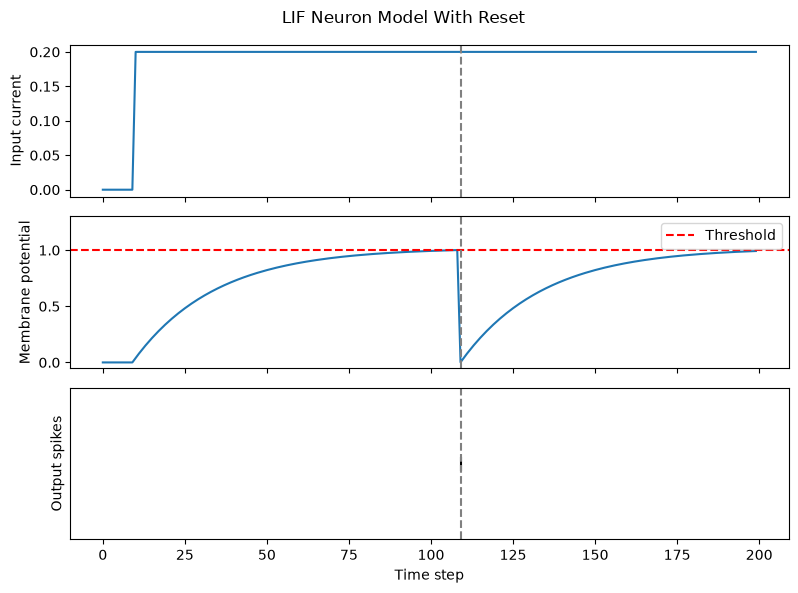

(<Figure size 800x600 with 3 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: ylabel='Membrane potential'>,
        <Axes: xlabel='Time step', ylabel='Output spikes'>], dtype=object))

In [21]:
# Small step current input
cur_in = torch.cat((torch.zeros(10), torch.ones(190)*0.2), 0)
mem = torch.zeros(1)
mem_rec = []
spk_rec = []

# neuron simulation
for step in range(num_steps):
  mem, spk = leaky_integrate_and_fire(mem, cur_in[step])
  mem_rec.append(mem)
  spk_rec.append(spk)

# convert lists to tensors
mem_rec = torch.stack(mem_rec)
spk_rec = torch.stack(spk_rec)

plot_cur_mem_spk(cur_in, mem_rec, spk_rec, thr_line=1, vline=109, ylim_max2=1.3,
                 title="LIF Neuron Model With Reset")

In [22]:
# Create the same neuron as before using snnTorch
lif2 = snn.Lapicque(R=5.1, C=5e-3, time_step=1e-3)

print(f"Membrane potential time constant: {lif2.R * lif2.C:.3f}s")

Membrane potential time constant: 0.025s


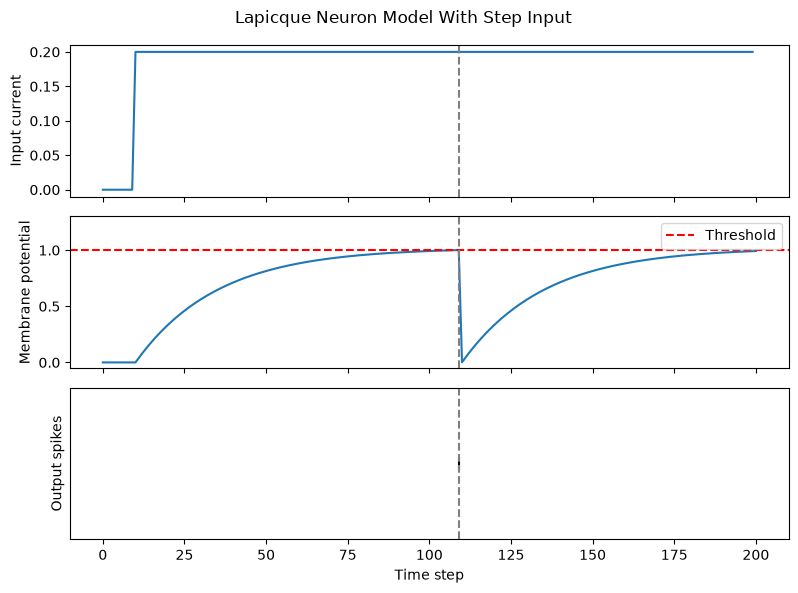

(<Figure size 800x600 with 3 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: ylabel='Membrane potential'>,
        <Axes: xlabel='Time step', ylabel='Output spikes'>], dtype=object))

In [23]:
# Initialize inputs and outputs
cur_in = torch.cat((torch.zeros(10, 1), torch.ones(190, 1)*0.2), 0)
mem = torch.zeros(1)
spk_out = torch.zeros(1)
mem_rec = [mem]
spk_rec = [spk_out]

# Simulation run across 100 time steps.
for step in range(num_steps):
  spk_out, mem = lif2(cur_in[step], mem)
  mem_rec.append(mem)
  spk_rec.append(spk_out)

# convert lists to tensors
mem_rec = torch.stack(mem_rec)
spk_rec = torch.stack(spk_rec)

plot_cur_mem_spk(cur_in, mem_rec, spk_rec, thr_line=1, vline=109, ylim_max2=1.3,
                 title="Lapicque Neuron Model With Step Input")

In [24]:
print(spk_rec[105:115].view(-1))

tensor([0., 0., 0., 0., 1., 0., 0., 0., 0., 0.])


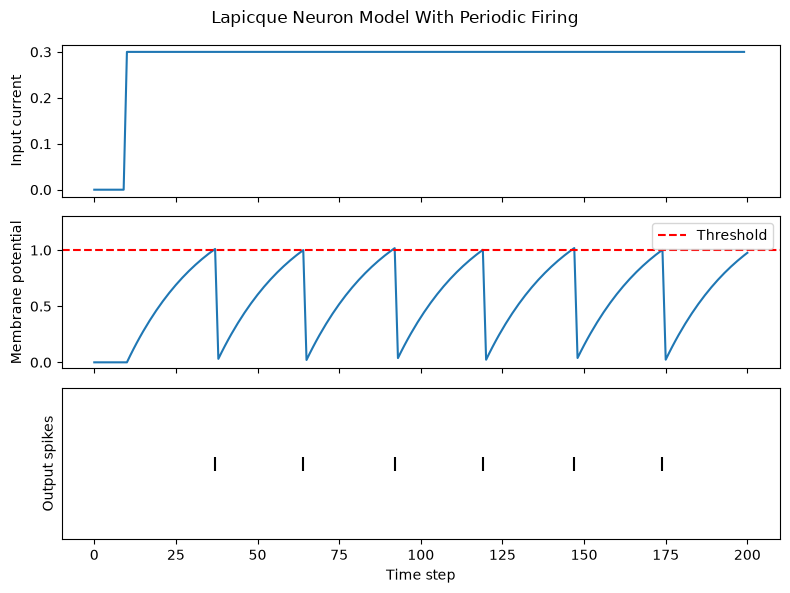

(<Figure size 800x600 with 3 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: ylabel='Membrane potential'>,
        <Axes: xlabel='Time step', ylabel='Output spikes'>], dtype=object))

In [25]:
# Initialize inputs and outputs
cur_in = torch.cat((torch.zeros(10, 1), torch.ones(190, 1)*0.3), 0)  # increased current
mem = torch.zeros(1)
spk_out = torch.zeros(1)
mem_rec = [mem]
spk_rec = [spk_out]

# neuron simulation
for step in range(num_steps):
  spk_out, mem = lif2(cur_in[step], mem)
  mem_rec.append(mem)
  spk_rec.append(spk_out)

# convert lists to tensors
mem_rec = torch.stack(mem_rec)
spk_rec = torch.stack(spk_rec)


plot_cur_mem_spk(cur_in, mem_rec, spk_rec, thr_line=1, ylim_max2=1.3,
                 title="Lapicque Neuron Model With Periodic Firing")

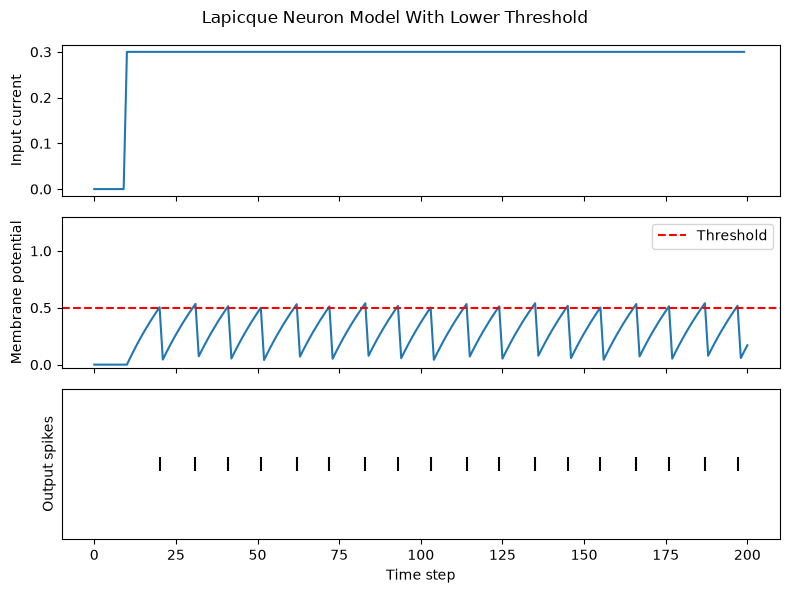

(<Figure size 800x600 with 3 Axes>,
 array([<Axes: ylabel='Input current'>,
        <Axes: ylabel='Membrane potential'>,
        <Axes: xlabel='Time step', ylabel='Output spikes'>], dtype=object))

In [26]:
# neuron with halved threshold
lif3 = snn.Lapicque(R=5.1, C=5e-3, time_step=1e-3, threshold=0.5)

# Initialize inputs and outputs
cur_in = torch.cat((torch.zeros(10, 1), torch.ones(190, 1)*0.3), 0)
mem = torch.zeros(1)
spk_out = torch.zeros(1)
mem_rec = [mem]
spk_rec = [spk_out]

# Neuron simulation
for step in range(num_steps):
  spk_out, mem = lif3(cur_in[step], mem)
  mem_rec.append(mem)
  spk_rec.append(spk_out)

# convert lists to tensors
mem_rec = torch.stack(mem_rec)
spk_rec = torch.stack(spk_rec)

plot_cur_mem_spk(cur_in, mem_rec, spk_rec, thr_line=0.5, ylim_max2=1.3,
                 title="Lapicque Neuron Model With Lower Threshold")

In [27]:
# Create a 1-D random spike train. Each element has a probability of 40% of firing.
spk_in = spikegen.rate_conv(torch.ones((num_steps,1)) * 0.40)

In [28]:
print(f"There are {int(sum(spk_in))} total spikes out of {len(spk_in)} time steps.")

There are 107 total spikes out of 200 time steps.


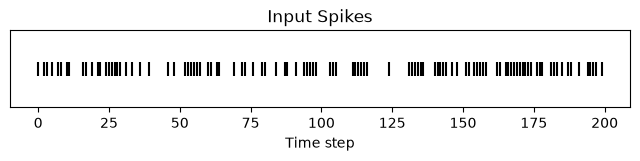

In [29]:
fig = plt.figure(facecolor="w", figsize=(8, 1))
ax = fig.add_subplot(111)

splt.raster(spk_in.reshape(num_steps, -1), ax, s=100, c="black", marker="|")
plt.title("Input Spikes")
plt.xlabel("Time step")
plt.yticks([])
plt.show()

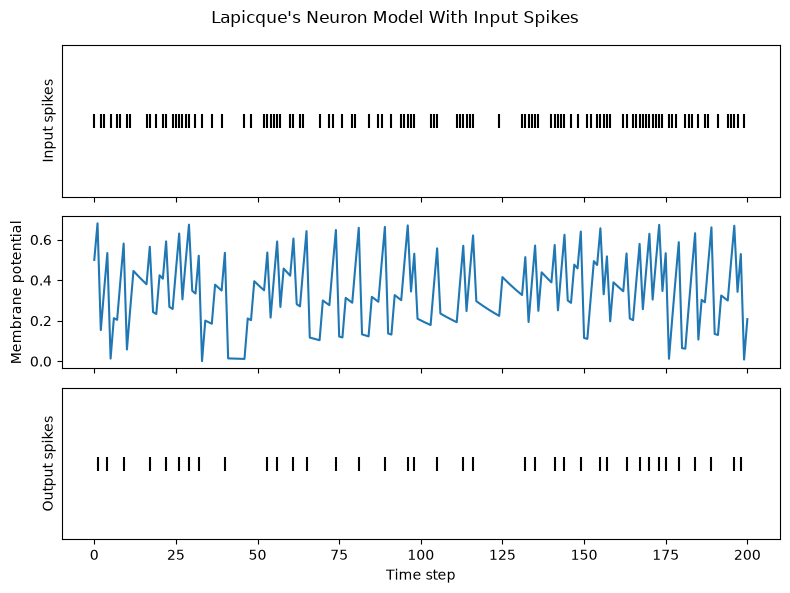

(<Figure size 800x600 with 3 Axes>,
 array([<Axes: ylabel='Input spikes'>, <Axes: ylabel='Membrane potential'>,
        <Axes: xlabel='Time step', ylabel='Output spikes'>], dtype=object))

In [30]:
# Initialize inputs and outputs
mem = torch.ones(1)*0.5
spk_out = torch.zeros(1)
mem_rec = [mem]
spk_rec = [spk_out]

# Neuron simulation
for step in range(num_steps):
  spk_out, mem = lif3(spk_in[step], mem)
  spk_rec.append(spk_out)
  mem_rec.append(mem)

# convert lists to tensors
mem_rec = torch.stack(mem_rec)
spk_rec = torch.stack(spk_rec)

plot_spk_mem_spk(spk_in, mem_rec, spk_rec, "Lapicque's Neuron Model With Input Spikes")

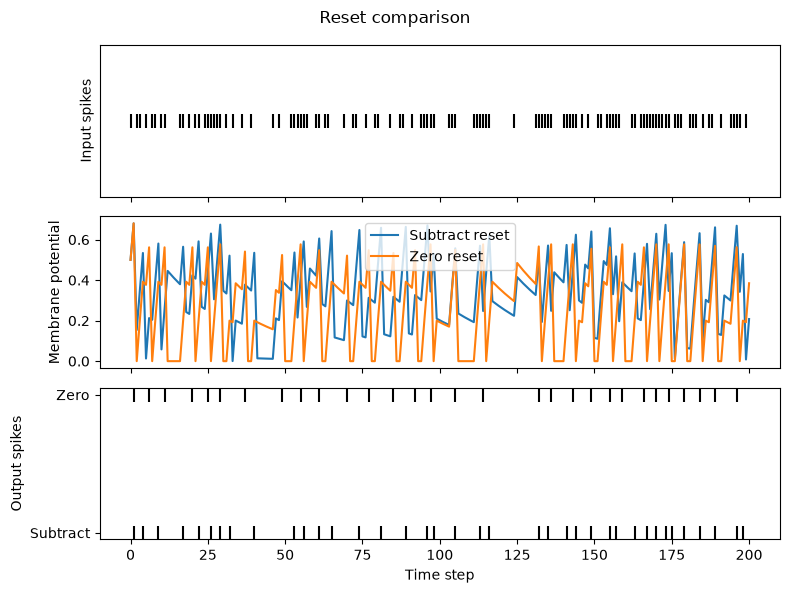

(<Figure size 800x600 with 3 Axes>,
 array([<Axes: ylabel='Input spikes'>, <Axes: ylabel='Membrane potential'>,
        <Axes: xlabel='Time step', ylabel='Output spikes'>], dtype=object))

In [31]:
# Neuron with reset_mechanism set to "zero"
lif4 = snn.Lapicque(R=5.1, C=5e-3, time_step=1e-3, threshold=0.5, reset_mechanism="zero")

# Initialize inputs and outputs
# Reuse spk_in so both reset modes receive the same input spikes.
mem = torch.ones(1)*0.5
spk_out = torch.zeros(1)
mem_rec0 = [mem]
spk_rec0 = [spk_out]

# Neuron simulation
for step in range(num_steps):
  spk_out, mem = lif4(spk_in[step], mem)
  spk_rec0.append(spk_out)
  mem_rec0.append(mem)

# convert lists to tensors
mem_rec0 = torch.stack(mem_rec0)
spk_rec0 = torch.stack(spk_rec0)

plot_reset_comparison(spk_in, mem_rec, spk_rec, mem_rec0, spk_rec0)